# Температурная характеристика датчиков RayNeo (RayDesk)

**Вопрос:** какие датчики и насколько «врут» при разных температурах — и сколько это даёт ухода мира.

**Данные** (`~/Library/Logs/RayDesk-imu`, пишутся автоматически):
- `imu-*.csv` — 500 Гц, сырой IMU: аксель в **g**, гироскоп в **°/с**, `temp` — термодатчик чипа IMU (°C), магнитометр. Хранятся последние 4 файла (~2 дня).
- `glasses-*.csv` — ~30 Гц, камера: `headingError` — расхождение курса IMU с курсом по камере (°), `cameraYawStep` — доворот мира за кадр (°), `score` — совпадение формы очков (%), `speed` — скорость головы.

**Как пользоваться:** Kernel → Restart & Run All. Новые логи подхватятся автоматически.

**Оси IMU:** в покое гравитация ≈ +Y, значит **gy — вертикальная ось (курс)**, gx/gz — горизонтальные (их биас уходит в наклон, который гравитация тут же компенсирует).


In [1]:
import sys
from datetime import datetime, timezone, timedelta
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
import sensorlib as sl

LOG_DIR = Path.home() / "Library/Logs/RayDesk-imu"
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 180)

def human(t):  # timeIntervalSinceReferenceDate → местное время
    return (datetime(2001, 1, 1, tzinfo=timezone.utc) + timedelta(seconds=float(t))).astimezone()


In [2]:
imu = sl.load_imu(LOG_DIR)
overview = imu.groupby("session").agg(
    start=("time", "first"), end=("time", "last"), rows=("time", "size"),
    t_min=("temp", "min"), t_max=("temp", "max"))
overview["минут"] = ((overview["end"] - overview["start"]) / 60).round(1)
overview["старт"] = overview["start"].map(lambda t: human(t).strftime("%d.%m %H:%M"))
print(f"{len(imu):,} строк, {imu['session'].nunique()} сессий(и) с температурой")
overview[["старт", "минут", "rows", "t_min", "t_max"]]


2,184,500 строк, 4 сессий(и) с температурой


,старт,минут,rows,t_min,t_max
session,,,,,
813079883,07.10 20:31,30.0,900000,22.68,39.25
813081683,07.10 21:01,30.0,900500,37.96,39.52
813083484,07.10 21:31,3.5,104000,38.15,38.55
813083741,07.10 21:35,9.3,280000,38.41,38.73


## Прогрев: температура IMU по сессиям

Внутри сессии видна рампа «надел холодные очки → датчик вышел на режим». Именно эти рампы дают разброс по температуре для всех следующих графиков.


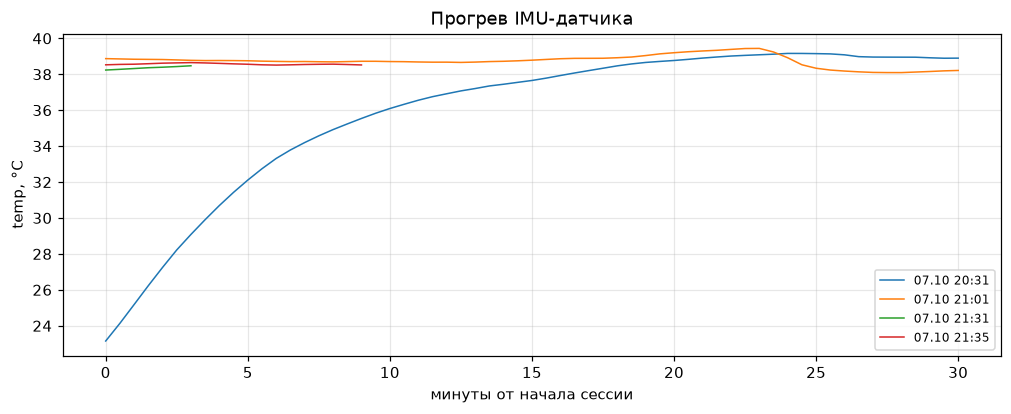

In [3]:
curve = sl.temp_curve(imu)
fig, ax = plt.subplots(figsize=(11, 3.8))
for sess, g in curve.groupby("session"):
    ax.plot(g["rel"] / 60, g["temp"], lw=1, label=f"{human(imu.loc[imu.session==sess,'time'].iloc[0]):%d.%m %H:%M}")
ax.set_xlabel("минуты от начала сессии"); ax.set_ylabel("temp, °C")
ax.set_title("Прогрев IMU-датчика"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.show()


## Гироскоп: биас в покое vs температура

В неподвижности истинная угловая скорость = 0, поэтому среднее гироскопа в сегменте неподвижности **и есть биас** (°/с). Опорой не пользуемся — это прямое измерение.
Наклон линии = дрейф биаса на °C. Вертикальная ось **gy** задаёт уход курса.


In [4]:
seg = sl.stillness_segments(imu)
print(f"сегментов неподвижности: {len(seg)}, суммарно {seg['dur'].sum()/60:.1f} мин, "
      f"temp {seg['temp'].min():.1f}–{seg['temp'].max():.1f} °C")
fits_gyro = {}
if len(seg) < 8 or seg["temp"].max() - seg["temp"].min() < 3:
    print("⚠️ В логах мало покоя (обычные сессии — постоянное движение) или узкий диапазон температур,")
    print("   фит ненадёжен. Чистый эксперимент из последней ячейки (5 мин покоя в холодных очках) заполнит график.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
    for ax_, axis in zip(axes, ["gx", "gy", "gz"]):
        a, b, r2, berr = sl.linfit(seg["temp"], seg[axis], seg["dur"])
        fits_gyro[axis] = {"a °/с": a, "°/ч на °C": sl.per_hour(b), "r²": r2, "±": sl.per_hour(berr)}
        ax_.scatter(seg["temp"], seg[axis], s=16, alpha=.55, c=seg["session"], cmap="tab10")
        xs = np.linspace(seg["temp"].min(), seg["temp"].max(), 10)
        ax_.plot(xs, a + b * xs, "r-", lw=1.5)
        ax_.set_title(f"{axis}: {sl.per_hour(b):+.2f} °/ч на °C (r²={r2:.2f})")
        ax_.set_xlabel("temp, °C"); ax_.grid(alpha=.3)
    axes[0].set_ylabel("биас, °/с")
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(fits_gyro).T)
seg[["session", "dur", "temp", "gx", "gy", "gz"]].round(3)


сегментов неподвижности: 1, суммарно 0.7 мин, temp 39.1–39.1 °C
⚠️ В логах мало покоя (обычные сессии — постоянное движение) или узкий диапазон температур,
   фит ненадёжен. Чистый эксперимент из последней ячейки (5 мин покоя в холодных очках) заполнит график.


,session,dur,temp,gx,gy,gz
0,813081683,43.887,39.142,-0.009,-0.007,-0.005


## Акселерометр: модуль и наклон vs температура

Скачок |a| = ошибка масштаба. Дрейф крена/тангажа, посчитанных из гравитации, = наклонная ошибка, которая напрямую двигает питч/ролл мира. Цвет точек — сессия.


In [5]:
fits_acc = {}
if len(seg) < 8 or seg["temp"].max() - seg["temp"].min() < 3:
    print("⚠️ Мало сегментов неподвижности — см. ячейку выше.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax_, col, name in zip(axes, ["amag", "roll", "pitch"],
                              ["|a|, g", "крен из гравитации, °", "тангаж из гравитации, °"]):
        a, b, r2, berr = sl.linfit(seg["temp"], seg[col], seg["dur"])
        fits_acc[col] = {"a": a, "на °C": b, "r²": r2, "±": berr}
        ax_.scatter(seg["temp"], seg[col], s=16, alpha=.55, c=seg["session"], cmap="tab10")
        xs = np.linspace(seg["temp"].min(), seg["temp"].max(), 10)
        ax_.plot(xs, a + b * xs, "r-", lw=1.5)
        ax_.set_title(f"{name}: {b:+.4f} на °C (r²={r2:.2f})")
        ax_.set_xlabel("temp, °C"); ax_.grid(alpha=.3)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(fits_acc).T)


⚠️ Мало сегментов неподвижности — см. ячейку выше.


## Магнитометр: модуль и курс vs температура

Модуль |m| — масштаб/мягкое железо. Курс по магнитометру зависит от того, куда смотришь, поэтому наклон считаем **внутри каждой сессии** (абсолютные уровни между сессиями несравнимы).


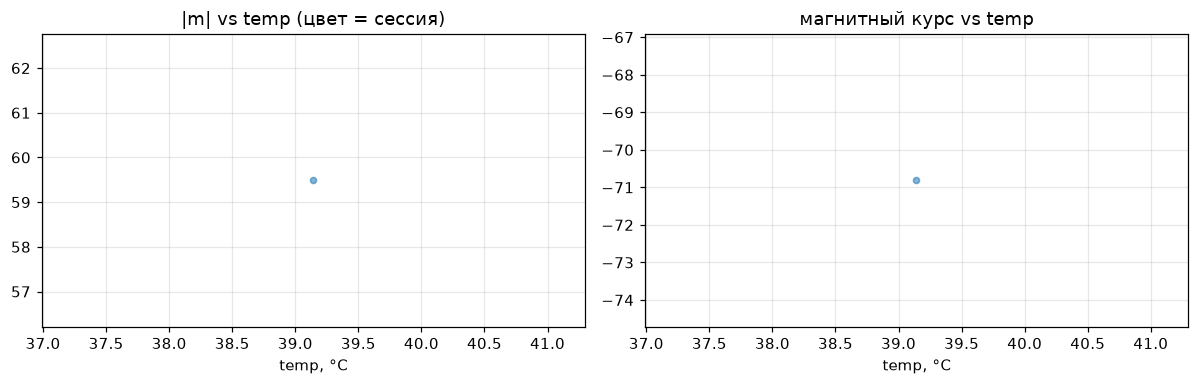

,a,на °C,r²,±
mmag,NaN,NaN,NaN,NaN


,сессия,n,ΔT °C,|m| на °C,|m| r²,курс °/ч на °C,курс r²
0,813081683,1,0.0,NaN,NaN,NaN,NaN


In [6]:
fits_mag = {"mmag": dict(zip(["a", "на °C", "r²", "±"],
            sl.linfit(seg["temp"], seg["mmag"], seg["dur"])))}
slopes = []
for sess, s in seg.dropna(subset=["m_yaw"]).groupby("session"):
    a, b, r2, berr = sl.linfit(s["temp"], s["m_yaw"], s["dur"])
    am, bm, r2m, _ = sl.linfit(s["temp"], s["mmag"], s["dur"])
    dt_ = s["temp"].max() - s["temp"].min()
    ok = dt_ >= 0.5  # фит на разбросе меньше 0.5 °C — мусор
    slopes.append({"сессия": sess, "n": len(s), "ΔT °C": dt_,
                   "|m| на °C": bm if ok else np.nan, "|m| r²": r2m if ok else np.nan,
                   "курс °/ч на °C": sl.per_hour(b) if ok else np.nan,
                   "курс r²": r2 if ok else np.nan})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].scatter(seg["temp"], seg["mmag"], s=16, alpha=.55, c=seg["session"], cmap="tab10")
axes[0].set_title("|m| vs temp (цвет = сессия)"); axes[0].set_xlabel("temp, °C"); axes[0].grid(alpha=.3)
for sess, s in seg.dropna(subset=["m_yaw"]).groupby("session"):
    axes[1].scatter(s["temp"], s["m_yaw"], s=16, alpha=.55, label=str(sess))
axes[1].set_title("магнитный курс vs temp"); axes[1].set_xlabel("temp, °C"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
display(pd.DataFrame(fits_mag).T, pd.DataFrame(slopes))


## Камера как абсолютная опора: скорость ухода курса vs температура и скорость поворота

Камера (MacBook) не плывёт с температурой очков, поэтому расхождение «IMU − камера» — независимая проверка.

- `derr` — скорость расхождения курса по окнам 10 с.
- `step_sum` — скорость доворотов мира камерой (корректор уже гасит ошибку).
- `true_rate = derr − step_sum` — полная скорость уплывания **до** коррекций: это и есть врёт ли гироскоп (остаточная, после компаса).

Зависимость от `speed` = ошибка **масштаба** гироскопа; от `temp` при покое = **биас**.
⚠️ 10-секундные окна шумные (камера ±0.5°): если r² у фита близок к нулю — тренд на этих данных не выделяется, нужна рампа из чистого эксперимента.


In [7]:
glasses = sl.load_glasses(LOG_DIR)
cam = sl.merge_temp(glasses, imu)
dr = sl.camera_drift_rate(cam)
dr["true_rate"] = dr["derr"] - dr["step_sum"]
dr_ok = dr[np.isfinite(dr["temp"])]
print(f"окон: {len(dr)} (из {len(glasses):,} кадров камеры), temp {dr_ok['temp'].min():.1f}–{dr_ok['temp'].max():.1f} °C")
dr_ok[["true_rate", "speed", "temp"]].describe().loc[["mean", "50%", "std"]]


окон: 2195 (из 1,162,110 кадров камеры), temp 23.2–39.5 °C


,true_rate,speed,temp
mean,-0.024194,1.713674,37.457652
50%,-0.002150,1.400000,38.635000
std,0.192830,1.211830,3.246693


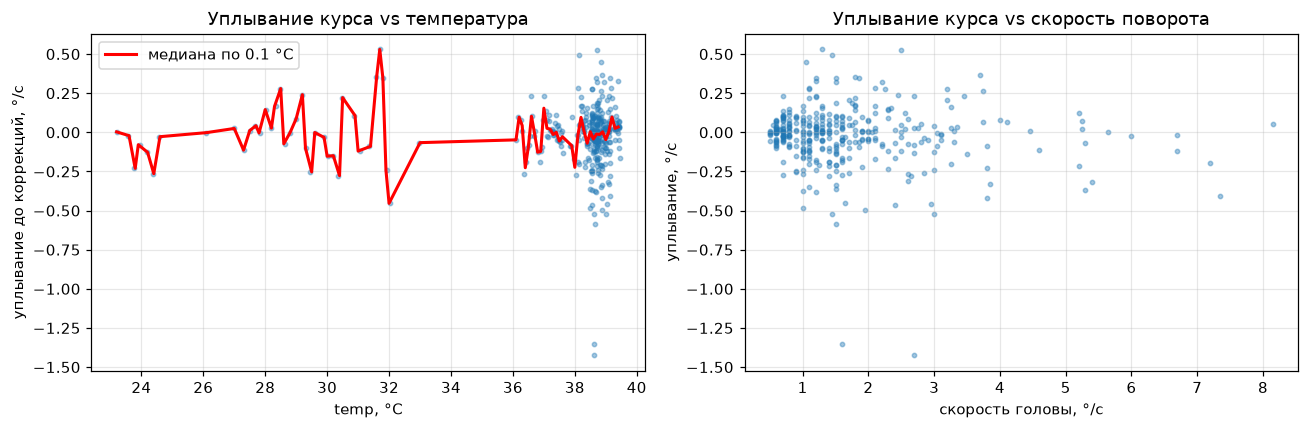

,условие,a °/ч,°/ч на °C,±,r²,окон
0,покой (<2°/с),144.680860,-5.516688,16.033772,0.000453,263
1,движение,22.897608,-4.702246,18.130492,0.000693,99


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d = dr_ok[dr_ok["true_rate"].abs() < 1.5]
axes[0].scatter(d["temp"], d["true_rate"], s=8, alpha=.4)
bins = d.assign(b=d["temp"].round(1)).groupby("b")["true_rate"].median()
axes[0].plot(bins.index, bins.values, "r-", lw=2, label="медиана по 0.1 °C")
axes[0].set_xlabel("temp, °C"); axes[0].set_ylabel("уплывание до коррекций, °/с")
axes[0].set_title("Уплывание курса vs температура"); axes[0].grid(alpha=.3); axes[0].legend()
axes[1].scatter(d["speed"], d["true_rate"], s=8, alpha=.4)
axes[1].set_xlabel("скорость головы, °/с"); axes[1].set_ylabel("уплывание, °/с")
axes[1].set_title("Уплывание курса vs скорость поворота"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

still = d[d["speed"] < 2]; moving = d[d["speed"] >= 2]
a_s, b_s, r2_s, e_s = sl.linfit(still["temp"], still["true_rate"])
a_m, b_m, r2_m, e_m = sl.linfit(moving["temp"], moving["true_rate"])
cam_fit = pd.DataFrame([
    {"условие": "покой (<2°/с)", "a °/ч": sl.per_hour(a_s), "°/ч на °C": sl.per_hour(b_s),
     "±": sl.per_hour(e_s), "r²": r2_s, "окон": len(still)},
    {"условие": "движение", "a °/ч": sl.per_hour(a_m), "°/ч на °C": sl.per_hour(b_m),
     "±": sl.per_hour(e_m), "r²": r2_m, "окон": len(moving)}])
cam_fit


### Накопленный доворот мира камерой по сессиям

Кумулятивная сумма `cameraYawStep` — история «как мир доворачивали, чтобы держать картинку». Рост = гироскоп уплывает; крутизна склона при прогеве видна на глаз.


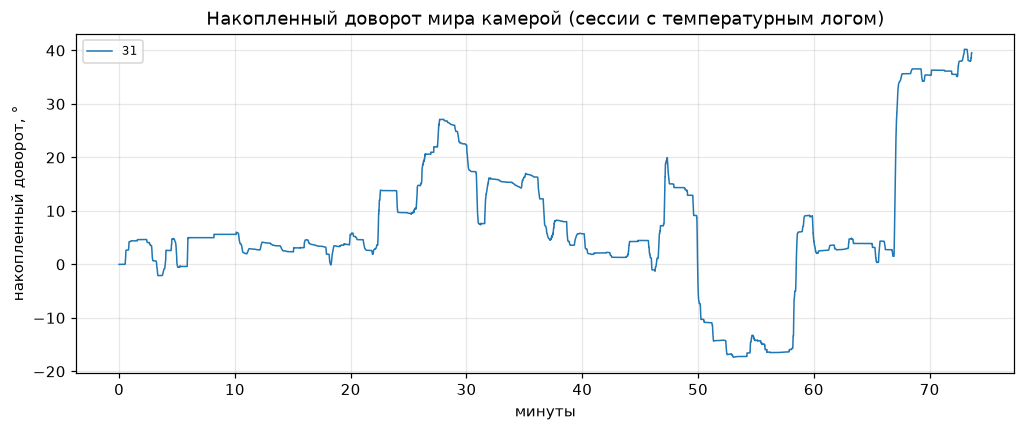

In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
for sess, s in cam[(cam["face"] == 1) & np.isfinite(cam["cameraYawStep"])].groupby("session"):
    if s["temp"].notna().mean() < 0.5:
        continue  # сессии без температурного лога IMU — до включения записи imu-*.csv
    s = s.sort_values("time")
    ax.plot((s["time"] - s["time"].iloc[0]) / 60, s["cameraYawStep"].clip(-2, 2).cumsum(), lw=1, label=str(sess))
ax.set_xlabel("минуты"); ax.set_ylabel("накопленный доворот, °")
ax.set_title("Накопленный доворот мира камерой (сессии с температурным логом)")
ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.show()


## Поворот головы: уплывает ли курс, пока голова стоит в стороне

**Метод.** Полка — окно ≥ 2.5 с, где камера видит **неподвижную** голову: курс по лицу не гуляет
(размах < 1.5°), очки не едут по кадру (< 10 мм), скорость из лога ниже 8 °/с. В таком окне камера
даёт ноль независимо от гироскопа, поэтому разница «вертикальная скорость гироскопа минус скорость
курса по камере» — это уход курса на ровном месте. Вертикальная ось берётся по локальной гравитации
(среднее ускорение окна), иначе наклон головы подмешивает горизонтальные оси.

Чем дальше голова отвёрнута, тем меньше полок — но именно они и интересны: боковые экраны
заставляют держать голову в стороне помногу.


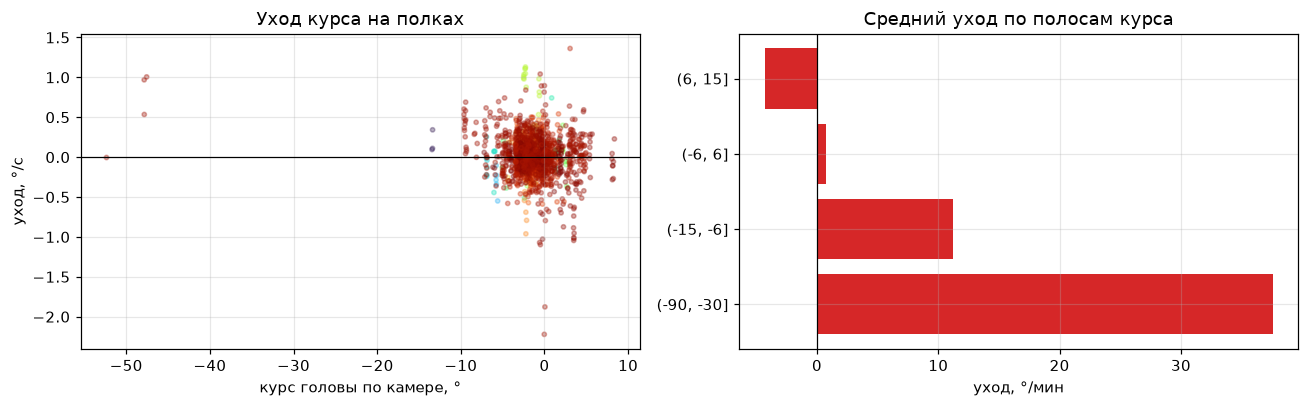

,полок,секунд,курс,гироскоп,камера,уход,разброс,temp,score,уход °/мин
band,,,,,,,,,,
"(-90, -30]",4,9.992,-48.901,0.632,0.006,0.626,0.472,38.705,0.703,37.552
"(-15, -6]",51,127.400,-8.130,0.171,-0.017,0.187,0.267,35.926,0.765,11.248
"(-6, 6]",1478,3692.025,-1.068,0.015,0.003,0.013,0.265,37.438,0.772,0.756
"(6, 15]",8,19.984,8.174,-0.017,0.055,-0.072,0.166,39.084,0.749,-4.309


In [10]:
plat = sl.head_plateaus(cam, imu)
by_band = plat.groupby("band", observed=True).agg(
    полок=("gyro_rate", "size"), секунд=("dur", "sum"), курс=("yaw", "mean"),
    гироскоп=("gyro_rate", "mean"), камера=("cam_rate", "mean"),
    уход=("rel_rate", "mean"), разброс=("rel_rate", "std"),
    temp=("temp", "mean"), score=("score", "mean"))
by_band["уход °/мин"] = by_band["уход"] * 60

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(plat["yaw"], plat["rel_rate"], s=8, alpha=.35, c=plat["temp"], cmap="turbo")
ax[0].axhline(0, color="k", lw=.8)
ax[0].set_xlabel("курс головы по камере, °"); ax[0].set_ylabel("уход, °/с")
ax[0].set_title("Уход курса на полках"); ax[0].grid(alpha=.3)
b = by_band.reset_index()
ax[1].barh([str(v) for v in b["band"]], b["уход °/мин"], color="C3")
ax[1].axvline(0, color="k", lw=.8); ax[1].set_xlabel("уход, °/мин")
ax[1].set_title("Средний уход по полосам курса"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

by_band.round(3)


### Уход мира относительно комнаты

Кватернион головы записан в мире, который приложение доворачивает коррекциями камеры. Курс из этого
кватерниона минус курс по камере — насколько картинка разошлась с комнатой: 0 = мир стоит там, где
стоит, рост = уезжает. Считается по кадрам с надёжным лицом, поэтому пики на быстрых поворотах —
запаздывание модели лица, а не уход. Разница зависит ещё и от позы головы (на удержании в стороне
модель лица врёт на единицы градусов), поэтому крайние точки сессии сравнивать нельзя — надёжен
только наклон по полкам с головой по центру.


,сессия,старт,минут,полок в центре,"уход крайних точек, °","наклон по сессии, °/мин","наклон на полках, °/мин","размах, °"
0,31,2026-10-07 20:31:24.280600+05:00,73.6,1478,-8.7,-0.08,-0.08,326.8


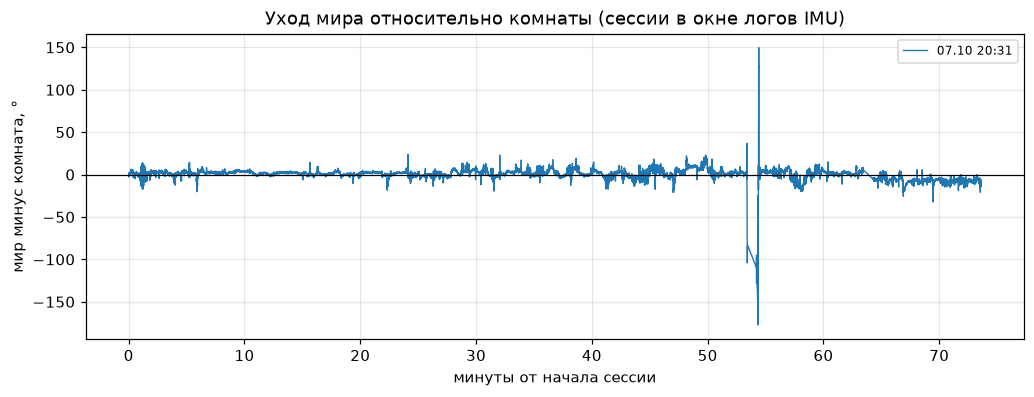

In [11]:
imu_t0 = imu["time"].min()
wd = sl.world_drift(cam)
wd = wd[wd["time"] >= imu_t0 - 60]        # только сессии, попавшие в окно логов IMU
rows = []
for sess, s in wd.groupby("session"):
    minutes = (s["time"].iloc[-1] - s["time"].iloc[0]) / 60
    if minutes < 3 or len(s) < 300:
        continue
    tc, rc = s["time"].to_numpy(), s["drift"].to_numpy()
    k = np.polyfit((tc - tc[0]) / 60, rc, 1)[0]
    # наклон только по полкам с головой по центру: уход мира зависит от позы,
    # поэтому крайние точки сессии сравнивать нельзя
    p = plat[(plat["t0"] >= tc[0]) & (plat["t0"] <= tc[-1]) & (plat["yaw"].abs() < 6)]
    kp = np.polyfit(p["t0"] - tc[0], np.interp(p["t0"], tc, rc), 1)[0] * 60 if len(p) > 20 else np.nan
    rows.append({"сессия": int(sess), "старт": human(tc[0]), "минут": round(minutes, 1),
                 "полок в центре": len(p),
                 "уход крайних точек, °": round(rc[-1] - rc[0], 1),
                 "наклон по сессии, °/мин": round(k, 2),
                 "наклон на полках, °/мин": round(kp, 2) if np.isfinite(kp) else np.nan,
                 "размах, °": round(np.ptp(rc), 1)})
drift_table = pd.DataFrame(rows)
display(drift_table)

fig, ax = plt.subplots(figsize=(11, 3.6))
for sess, s in wd.groupby("session"):
    if len(s) < 300: continue
    ax.plot((s["time"] - s["time"].iloc[0]) / 60, s["drift"] - s["drift"].iloc[0],
            lw=.9, label=human(s["time"].iloc[0]).strftime("%d.%m %H:%M"))
ax.axhline(0, color="k", lw=.8)
ax.set_xlabel("минуты от начала сессии"); ax.set_ylabel("мир минус комната, °")
ax.set_title("Уход мира относительно комнаты (сессии в окне логов IMU)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.show()


### Прошивка очков сама пересчитывает ноль гироскопа

`imu-*.csv` пишется **до** обработки в приложении: это сырые показания прошивки. Показания квантованы
шагом 0.035 °/с, а своё смещение нуля прошивка сдвигает на среднее последних 2 с — и делает это,
когда ей кажется, что очки лежат неподвижно, в том числе на медленном повороте головы. Каждый сдвиг
меняет показания скачком, поэтому курс на секунды уезжает со скоростью до 2–3 °/с, пока смещение не
пересчитается снова.

В приложении для этого есть `FirmwareZeroRestorer` (`RayDeskCore`) и `firmware_zero_restore` здесь —
точный порт: он складывает скачки обратно и возвращает постоянный ноль. Включается пунктом меню
**Камера → «Отменять пересчёты нуля гироскопа прошивкой»**, по умолчанию включён.

**Переключение стоит пережить.** Замер 07.10 21:35–21:43: сразу после включения накопленный сдвиг
дошёл до 2.5 °/с, фильтр выучил новый ноль (1.7 −2.3 −2.0 °/с вместо ±0.2), и в эту минуту камера
довернула мир на +30°. Дальше мир стоит: по минутам +2.4, +0.1, +0.5, 0.0, −0.7, headingError в
медиане +0.07°. Причина понятна: отмена пересчётов оставляет фильтру настоящий уход биаса прогретого
датчика (до 2 °/с), и его надо выучить заново — на переключение уходит минута.


In [12]:
gyro_raw = imu[["gx", "gy", "gz"]].to_numpy()
gyro_fixed = np.empty_like(gyro_raw)
firmware_events = []
for a, b in sl.imu_runs(imu):
    if b - a < 5:
        gyro_fixed[a:b] = gyro_raw[a:b]; continue
    fixed, ev = sl.firmware_zero_restore(gyro_raw[a:b])
    gyro_fixed[a:b] = fixed
    if len(ev):
        ev = ev.assign(time=imu["time"].to_numpy()[a:b][ev["i"].to_numpy()])
        firmware_events.append(ev)
firmware_events = pd.concat(firmware_events, ignore_index=True) if firmware_events else pd.DataFrame()

active = sum(b - a for a, b in sl.imu_runs(imu) if b - a > 5) / 500   # секунд записи без пауз
print(f"пересчётов нуля прошивкой: {len(firmware_events)} за {active/60:.0f} мин работы "
      f"(в среднем раз в {active/max(len(firmware_events),1):.1f} с)")
if len(firmware_events):
    step = firmware_events[["dx", "dy", "dz"]].to_numpy()
    print(f"скачок смещения: медиана {np.median(np.abs(step).max(1)):.3f} °/с, "
          f"p90 {np.percentile(np.abs(step).max(1), 90):.3f} °/с, макс {np.abs(step).max():.3f} °/с")

firmware_events.assign(минута=lambda d: ((d["time"] - imu["time"].iloc[0]) / 60).round(1),
                       скачок=lambda d: np.abs(d[["dx", "dy", "dz"]].to_numpy()).max(1).round(3)
                       ).sort_values("скачок", ascending=False)[["минута", "dx", "dy", "dz", "скачок"]].head(8).round(3)


пересчётов нуля прошивкой: 517 за 73 мин работы (в среднем раз в 8.5 с)
скачок смещения: медиана 0.260 °/с, p90 0.968 °/с, макс 2.248 °/с


,минута,dx,dy,dz,скачок
259,39.1,-2.248,-0.113,-0.499,2.248
442,66.4,-1.812,0.136,2.105,2.105
258,39.0,1.981,0.194,0.345,1.981
441,66.4,1.100,0.120,-1.885,1.885
189,24.8,1.877,0.135,-0.145,1.877
467,69.2,-1.825,-0.319,-0.048,1.825
415,62.2,1.774,-0.197,0.502,1.774
466,69.2,1.757,-0.053,-0.058,1.757


### Что это значит для ухода

- Уход мира по полкам с головой по центру — сотые доли °/мин во всех трёх сессиях: в покое картинка
  стоит. На быстрых поворотах «уход крайних точек» в таблице выше — это поза, а не дрейф.
- Полки в логе показывают: пока голова стоит по центру, гироскоп и камера совпадают (уход ~0.01 °/с),
  а на удержании головы в стороне гироскоп «едет» влево — до 0.6 °/с на −49° (это 38 °/мин, за 20 с
  удержания пара десятков градусов, если бы камера не подтягивала мир).
- Скачки нуля прошивки — второй, независимый механизм: каждый скачок сдвигает весь дальнейший курс,
  пока не пересчитается. Лечится включением `restoreFirmwareZero`.
- Смотреть на температуру здесь не нужно: на полках уход от 20 до 39 °C одинаковый.


## Сводка: кто и насколько врёт

Проекция на мир: за час при прогреве на ΔT от 30 °C до 38 °C, без компаса и камеры.


In [13]:
dT = 8.0
rows = []
g = fits_gyro.get("gy", {}).get("°/ч на °C", np.nan)
rows.append({"датчик": "гироскоп gy (курс), биас",
             "эффект": f"{g:+.2f} °/ч на °C" if np.isfinite(g) else "мало покоя в логах",
             "уход за час при ΔT=8°": f"{g*dT:+.1f}°" if np.isfinite(g) else "н/д"})
for name, col in [("крен (гравитация)", "roll"), ("тангаж (гравитация)", "pitch")]:
    b = fits_acc.get(col, {}).get("на °C", np.nan)
    rows.append({"датчик": f"аксель → {name}",
                 "эффект": f"{b:+.4f} ° на °C" if np.isfinite(b) else "мало покоя в логах",
                 "уход за час при ΔT=8°": f"{b*dT:+.2f}°" if np.isfinite(b) else "н/д"})
bm = fits_mag["mmag"]["на °C"]
rows.append({"датчик": "магнитометр |m|", "эффект": f"{bm:+.5f} на °C", "уход за час при ΔT=8°": "—"})
for _, r in cam_fit.iterrows():
    v = r["°/ч на °C"]
    rows.append({"датчик": f"курс vs камера, {r['условие']}",
                 "эффект": f"{v:+.2f} °/ч на °C",
                 "уход за час при ΔT=8°": f"{v*dT:+.1f}°" if np.isfinite(v) else "н/д"})
summary = pd.DataFrame(rows)
summary


,датчик,эффект,уход за час при ΔT=8°
0,"гироскоп gy (курс), биас",мало покоя в логах,н/д
1,аксель → крен (гравитация),мало покоя в логах,н/д
2,аксель → тангаж (гравитация),мало покоя в логах,н/д
3,магнитометр |m|,+nan на °C,—
4,"курс vs камера, покой (<2°/с)",-5.52 °/ч на °C,-44.1°
5,"курс vs камера, движение",-4.70 °/ч на °C,-37.6°


## Методика чистого эксперимента (если захочется точнее)

Текущих логов уже хватает для грубых коэффициентов, но для чистого измерения:

1. **Охладить** выключенные очки 10–15 минут (у открытого окна, осенью выйдет ~15–18 °C).
2. Надеть, включить wall mode + трекинг по очкам, сесть.
3. **5 минут неподвижно** — чистая рампа биаса от холодного к тёплому.
4. Потом 15 минут обычной работы: каждые ~3 минуты медленный поворот в сторону до упора и обратно, на возврате — метка **⌃⌥M**.
5. Здесь: *Restart & Run All* — сессия с самым большим ΔT будет видна на графике прогрева; все коэффициенты пересчитаются сами.

**Куда это применить:** если биас gy и/или масштаб линейно зависят от T (r² заметно > 0), в `OrientationFilter`/`StillnessBiasLearner` можно добавить компенсацию по температуре — та же логика, что у `gyroScale`, только коэффициент на °C.
